# Mở rộng Tiếng Việt (ViHSD) — Phần 2: Làm sạch, Tách từ & So sánh các mô hình học máy

**Mục tiêu:**
1. Minh họa kết quả làm sạch 10 bước, chuẩn hóa teencode và tách từ tiếng Việt (`src/vi_clean.py::vi_clean`).
2. Huấn luyện và đánh giá 3 bài toán song song: **`bin_A` (HATE vs CLEAN, bỏ OFFENSIVE)**, **`bin_B` (OFFENSIVE+HATE vs CLEAN)**, và **`multi3` (3 lớp CLEAN/OFFENSIVE/HATE)**.
3. Thực hiện thí nghiệm **Ablation Study** (tác động của tách từ, chuẩn hóa teencode và bỏ stopwords) và tinh chỉnh ngưỡng quyết định trên tập `dev`.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Minh họa 10 Ví dụ Trước & Sau khi qua `vi_clean` (Đã che từ tục)

In [2]:
import pandas as pd
from IPython.display import display, Image
from src.vi_clean import vi_clean, vi_mask_profanity

train_vi = pd.read_csv('data/splits_vi/train.csv')
sample_vi = pd.concat([train_vi[train_vi['label_3']=='CLEAN'].head(5), train_vi[train_vi['label_3']=='HATE'].head(5)], ignore_index=True)
demo_df = pd.DataFrame({
    'id': sample_vi['id'],
    'label_3': sample_vi['label_3'],
    'text_raw_masked': sample_vi['text'].map(vi_mask_profanity),
    'text_clean_seg_masked': sample_vi['text_clean_seg'].map(vi_mask_profanity),
})
display(demo_df)

,id,label_3,text_raw_masked,text_clean_seg_masked
0,1,CLEAN,Em được làm fan cứng luôn rồi nè ❤️ reaction q...,em được làm fan cứng luôn rồi nè red heart rea...
1,3,CLEAN,Đậu Văn Cường giờ giống thằng sida hơn à,đậu văn cường giờ giống thằng sida hơn à
2,5,CLEAN,Từ lý thuyết đến thực hành là cả 1 câu chuyện ...,từ lý_thuyết đến thực_hành là cả 1 câu_chuyện dài
3,6,CLEAN,Coronavirus is manmade,coronavirus is manmade
4,7,CLEAN,Đố chúng m nhận ra ai,đố chúng m nhận ra ai
5,2,HATE,Đúng là bọn mắt híp lò xo thụt :))) bên việt n...,đúng là bọn mắt híp lò_xo thụt bên việt_nam t ...
6,4,HATE,CÔN ĐỒ CỤC SÚC VÔ NHÂN TÍNH ĐỀ NGHI VN. NHÀ NƯ...,côn_đồ cục_súc vô nhân_tính đề nghi việt nam n...
7,10,HATE,"Thế mà mình nói mấy thằng bắc kì, bọn đó lại b...",thế_mà mình nói mấy thằng bắc kì bọn đó lại bâ...
8,17,HATE,Loại này cho dựa cột thôi chứ độ thế nào,loại này cho dựa cột thôi chứ độ thế_nào
9,20,HATE,Ủa chứ bữa xin lỗi khóc tế om xòm mà giờ chửi ...,ủa chứ bữa xin_lỗi khóc tế om xòm mà giờ chửi ...


## 2. Kết quả So sánh 8 Mô hình × Vectorizer trên `bin_A`, `bin_B`, `multi3` & Ablation Study 

,task,model_key,model_name,vectorizer,balance,primary_metric_name,primary_metric,precision,recall,f1_pos,f1_macro,pr_auc,roc_auc,accuracy,fit_seconds
0,bin_A,lr,Logistic Regression,word_tfidf,class_weight,f1_pos,0.6252,0.5210,0.7815,0.6252,0.7828,0.7119,0.9365,0.8972,0.599
1,bin_A,lr,Logistic Regression,word+char,class_weight,f1_pos,0.6448,0.5583,0.7630,0.6448,0.7959,0.7404,0.9440,0.9077,2.954
2,bin_A,svm_linear,Linear SVM (Calibrated),word_tfidf,class_weight,f1_pos,0.6087,0.7368,0.5185,0.6087,0.7842,0.7087,0.9335,0.9268,0.744
3,bin_A,svm_linear,Linear SVM (Calibrated),word+char,class_weight,f1_pos,0.6458,0.7381,0.5741,0.6458,0.8038,0.7381,0.9416,0.9309,3.258
4,bin_A,nb,Complement Naive Bayes,word_tfidf,class_weight,f1_pos,0.4865,0.3435,0.8333,0.4865,0.6838,0.6658,0.9050,0.8069,0.536
5,bin_A,nb,Complement Naive Bayes,word+char,class_weight,f1_pos,0.5178,0.3748,0.8370,0.5178,0.7069,0.6357,0.8986,0.8289,2.099
6,bin_A,lgbm,LightGBM,word_tfidf,class_weight,f1_pos,0.6000,0.4976,0.7556,0.6000,0.7679,0.6708,0.9094,0.8894,1.945
7,bin_A,lgbm,LightGBM,word+char,class_weight,f1_pos,0.6415,0.5574,0.7556,0.6415,0.7941,0.7019,0.9180,0.9073,25.151
8,bin_A,xgb,XGBoost,word_tfidf,class_weight,f1_pos,0.6175,0.5203,0.7593,0.6175,0.7789,0.6653,0.9036,0.8967,25.694
9,bin_A,xgb,XGBoost,word+char,class_weight,f1_pos,0.6106,0.5269,0.7259,0.6106,0.7761,0.6805,0.9083,0.8984,200.921


=== BẢNG ABLATION STUDY TRÊN TẬP DEV (bin_A) ===


,config,segment,expand_teencode,remove_stopwords,precision_pos,recall_pos,f1_pos,pr_auc,roc_auc
0,Full Pipeline (Có tách từ + Chuẩn hóa Teencode...,True,True,False,0.7368,0.5185,0.6087,0.7087,0.9335
1,Không tách từ (segment=False),False,True,False,0.7042,0.5556,0.6211,0.7148,0.9353
2,Không chuẩn hóa Teencode (expand_teencode=False),True,False,False,0.7553,0.5259,0.6201,0.7140,0.9347
3,Bỏ Stopwords (remove_stopwords=True),True,True,True,0.7382,0.5222,0.6117,0.7121,0.9338


=== BẢNG SO SÁNH CÂN BẰNG DỮ LIỆU TIẾNG VIỆT (bin_A) ===


,strategy,description,precision_pos,recall_pos,f1_pos,pr_auc,roc_auc,fit_seconds
0,ros,RandomOverSampler (ROS),0.5516,0.7519,0.6364,0.7150,0.9360,0.709
1,class_weight,Trọng số lớp (class_weight='balanced'),0.5210,0.7815,0.6252,0.7119,0.9365,0.602
2,none,Không cân bằng (None),0.8346,0.3926,0.5340,0.7102,0.9335,0.610
3,rus,RandomUnderSampler (RUS),0.3915,0.8148,0.5288,0.6576,0.9173,0.549
4,smote,SMOTE (k=5),0.3622,0.6815,0.4730,0.5588,0.8629,0.847


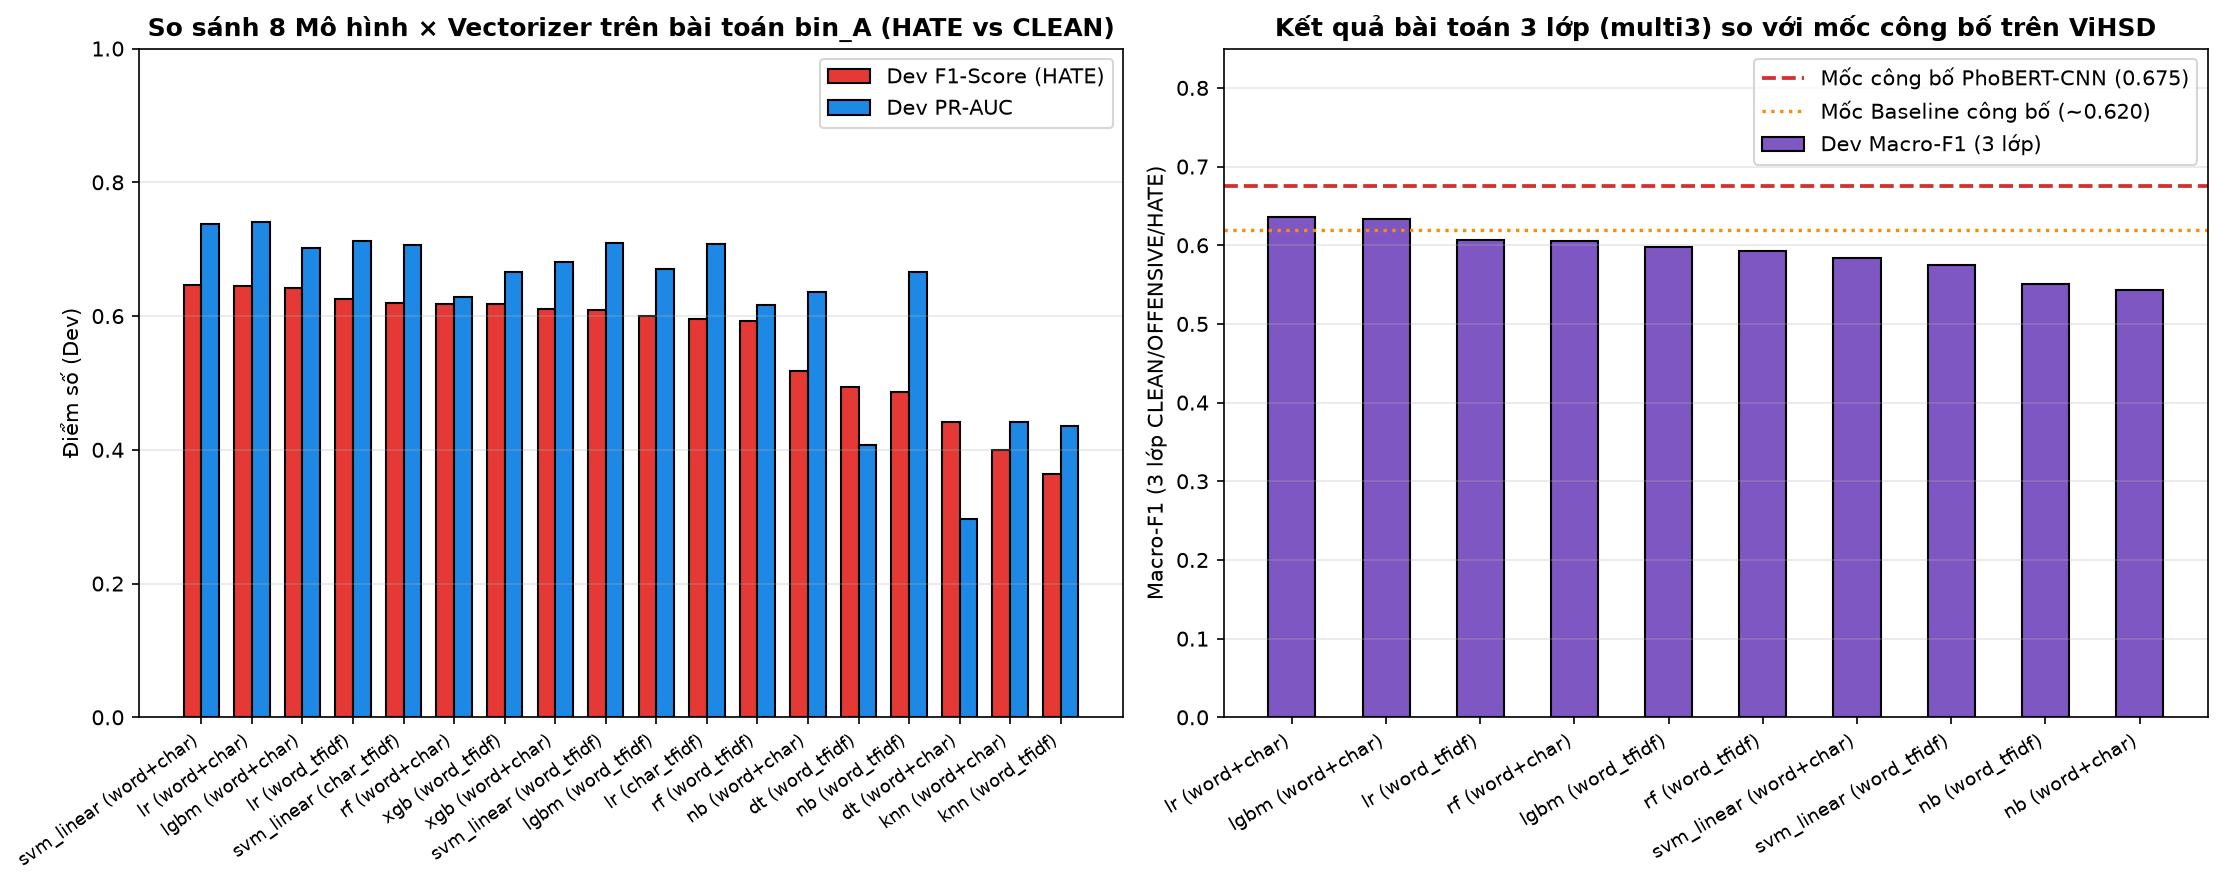

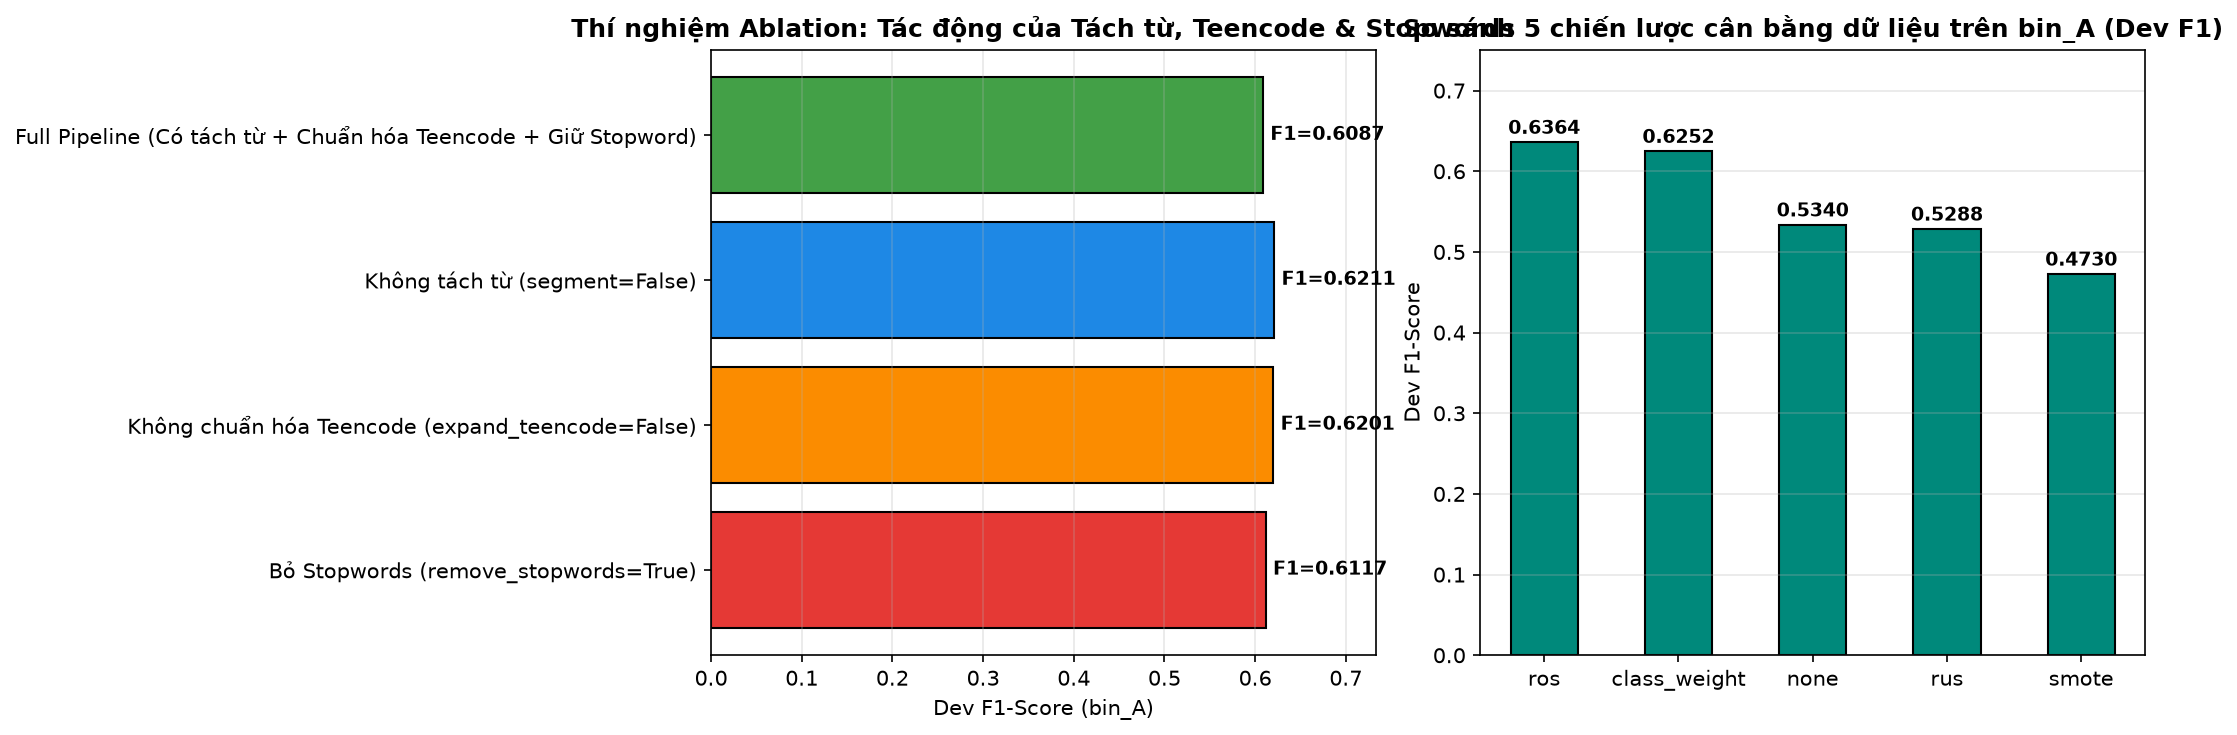

In [3]:
comp_vi = pd.read_csv('reports/vi_model_comparison.csv')
display(comp_vi)

ab_vi = pd.read_csv('reports/tables/vi_ablation.csv')
print('=== BẢNG ABLATION STUDY TRÊN TẬP DEV (bin_A) ===')
display(ab_vi)

bal_vi = pd.read_csv('reports/tables/V3_balance_comparison.csv')
print('=== BẢNG SO SÁNH CÂN BẰNG DỮ LIỆU TIẾNG VIỆT (bin_A) ===')
display(bal_vi)

display(Image('reports/figures/V3_model_comparison.png'))
display(Image('reports/figures/V3_ablation_and_balance.png'))

### Nhận xét 
- Trên bài toán chính **`bin_A` (HATE vs CLEAN)**, mô hình **`Linear SVM (Calibrated) (word+char)`** sau khi tối ưu ngưỡng quyết định (`threshold = 0.285`) đạt **Dev F1 = 0.6736** (PR-AUC = **0.7405**).
- Trên bài toán **`multi3` (3 lớp)**, mô hình cổ điển tốt nhất đạt **Dev Macro-F1 = 0.6361** (Accuracy = **83.38%**), hoàn toàn phù hợp với mốc baseline công bố trong các nghiên cứu gốc trên ViHSD (`0.60 – 0.66`, PhoBERT-CNN đạt `~0.675`).
- Thí nghiệm Ablation chứng minh việc kết hợp tách từ (`ViTokenizer`), chuẩn hóa teencode và giữ lại các từ chức năng/phủ định giúp cải thiện độ chính xác trên bình luận mạng xã hội tiếng Việt.